# 数字1・1枚のLSHシートの理論検証

圧縮データを使わず、数字1の目標画像から各ThreadのFrozen Wave係数を計算します。無限開口の解析解、有限開口の複素場の伝搬、振幅も符号化した8-bit位相CGH＋理想4fフィルタの伝搬を比較します。

**数字1はy=0のx–z面に現れる設計です。** センサーが各zで撮るのはx–y面です。その画像のy=0の横断線をz方向に並べてシートを確認します。固定zのセンサー画像1枚に数字1が出る設計ではありません。

初期条件：532 nm、中心モードの第1零点半径50 µm、2048×2048、数値ピッチ3.74 µm、21 Thread・75 µm間隔、z=0〜50 cm・101点。理想4f出力面をz=0とし、実機SLM座標・倍率への換算は含めません。詳細は `LSH数字1_理論検証.md`。


In [1]:
import importlib
import lsh_digit1_theory as theory
theory = importlib.reload(theory)
config = theory.Digit1Config()
# 伝搬のパディング比較も行う場合：config = theory.Digit1Config(check_padding=True)
# CGH再生を含めず複素場だけを確認する場合：include_cgh_replay=False
output_dir = 'lsh_digit1_theory_outputs_v1'
design = theory.mode_design(config)
print('コード:', theory.__file__)
print('モード数/Thread:', design.count, 'm:', design.m)
print('Thread数:', config.thread_count, '間隔[µm]:', config.thread_spacing_m * 1e6)
print('z範囲[mm]:', 0, config.design_length_m * 1e3, '撮影位置数:', config.z_samples)
print('保存先:', output_dir)


コード: c:\Users\kota-\Github\Project_new\research\lsh_digit1_theory.py
モード数/Thread: 15 m: [-7 -6 -5 -4 -3 -2 -1  0  1  2  3  4  5  6  7]
Thread数: 21 間隔[µm]: 75.0
z範囲[mm]: 0 500.0 撮影位置数: 101
保存先: lsh_digit1_theory_outputs_v1


In [2]:
from dataclasses import asdict
from pathlib import Path
import json
result_dir = Path(output_dir)
summary_file = result_dir / 'summary.json'
expected_config = theory.config_payload(config)
if summary_file.is_file() and (result_dir / 'manifest.json').is_file():
    summary = json.loads(summary_file.read_text(encoding='utf-8'))
    if (summary.get('study') != 'theory_only_digit1_single_xz_sheet'
            or summary.get('schema_version') != theory.THEORY_SCHEMA_VERSION
            or theory.config_payload(summary.get('config', {})) != expected_config):
        raise ValueError('旧結果または別設定です。output_dirを新しい名前に変更してください。')
    print('同じ条件の保存結果を読み込みました。')
elif result_dir.exists() and any(result_dir.iterdir()):
    raise ValueError('途中結果があります。output_dirを新しい名前に変更してください。')
else:
    summary = theory.run_digit1(result_dir, config)
print('結果:', result_dir.resolve())
print('実際に係数が非零のThread数:', summary['active_thread_count'])
for case, metrics in summary['metrics'].items():
    print(case, metrics)
print('CGH符号化・4f出力の評価:', summary['encoding'])
print('パディングの確認:', summary['padding_validation'])


Initial field: thread 5/21
Initial field: thread 6/21
Initial field: thread 7/21
Initial field: thread 8/21
Initial field: thread 9/21
Initial field: thread 10/21
Initial field: thread 11/21
Initial field: thread 12/21
Initial field: thread 13/21
Initial field: thread 14/21
Initial field: thread 15/21
Initial field: thread 16/21
Initial field: thread 17/21
Sensor propagation: 1/101, z=0.0 mm
Sensor propagation: 6/101, z=25.0 mm
Sensor propagation: 11/101, z=50.0 mm
Sensor propagation: 16/101, z=75.0 mm
Sensor propagation: 21/101, z=100.0 mm
Sensor propagation: 26/101, z=125.0 mm
Sensor propagation: 31/101, z=150.0 mm
Sensor propagation: 36/101, z=175.0 mm
Sensor propagation: 41/101, z=200.0 mm
Sensor propagation: 46/101, z=225.0 mm
Sensor propagation: 51/101, z=250.0 mm
Sensor propagation: 56/101, z=275.0 mm
Sensor propagation: 61/101, z=300.0 mm
Sensor propagation: 66/101, z=325.0 mm
Sensor propagation: 71/101, z=350.0 mm
Sensor propagation: 76/101, z=375.0 mm
Sensor propagation: 81/1

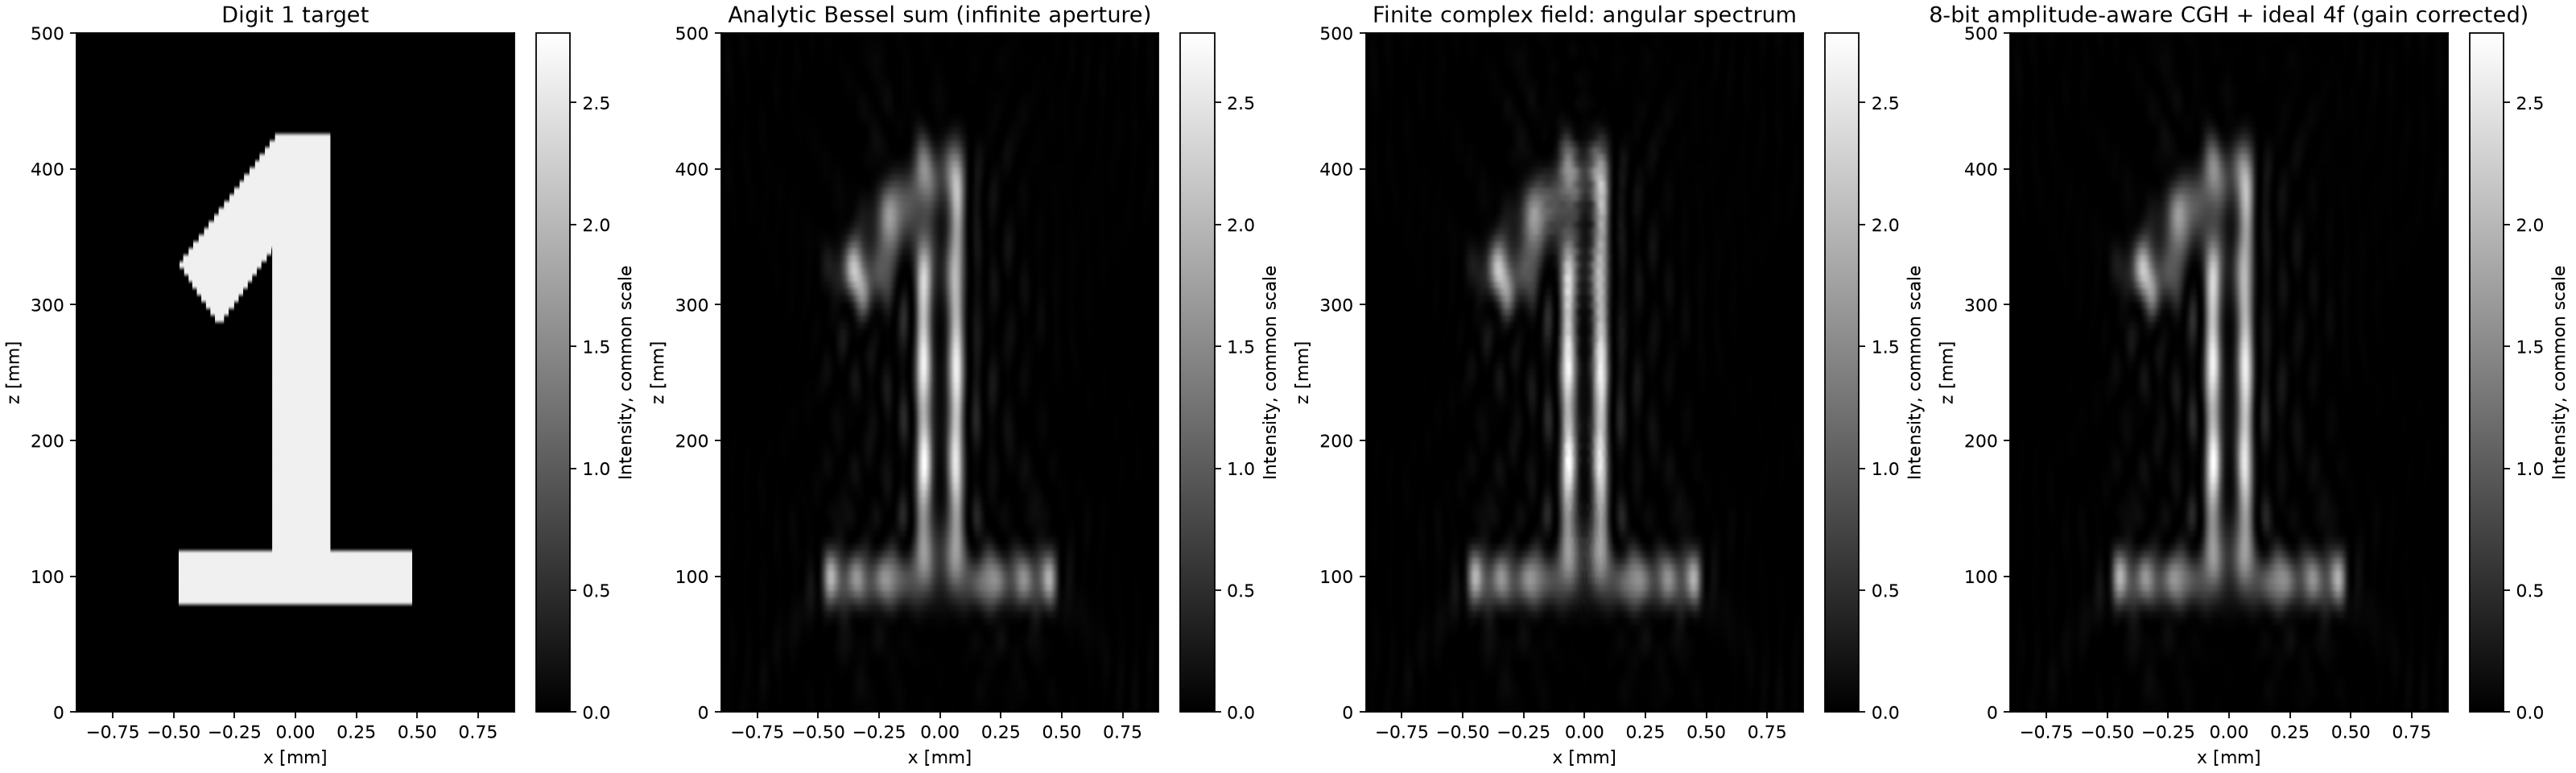

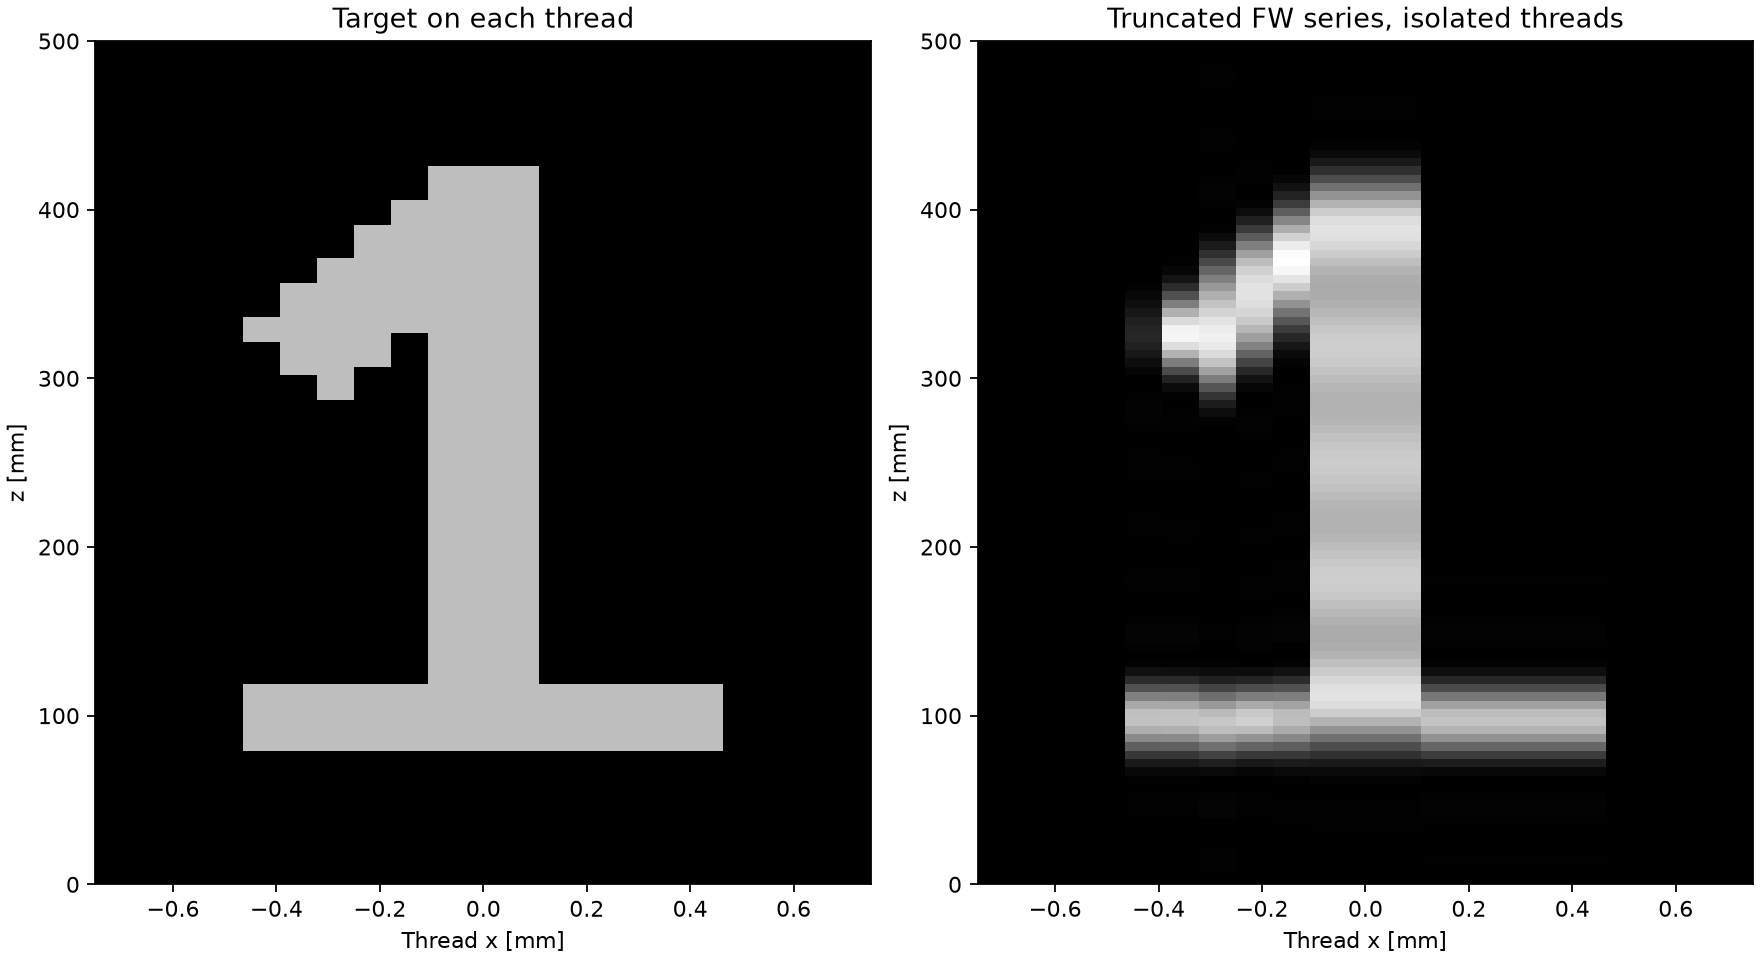

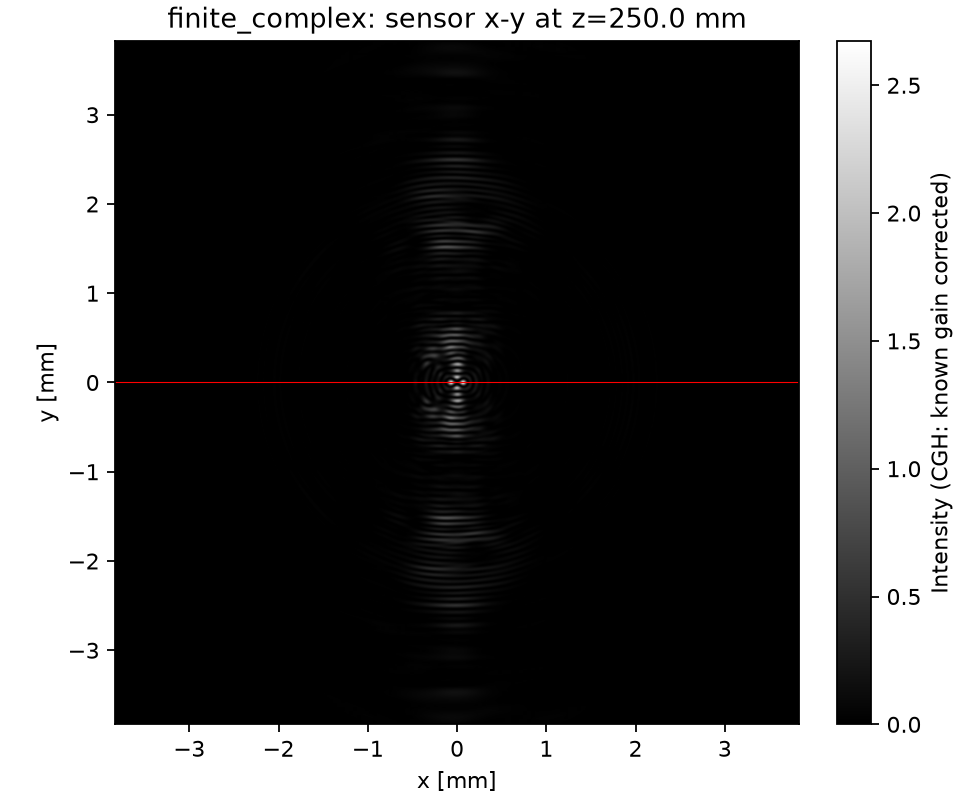

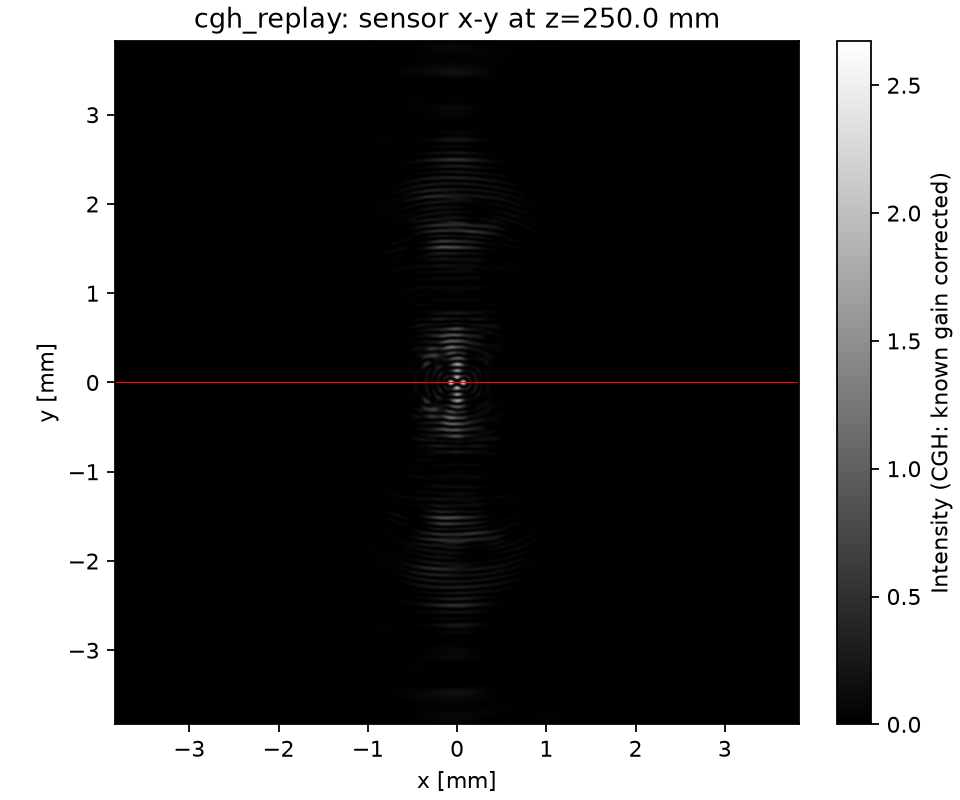

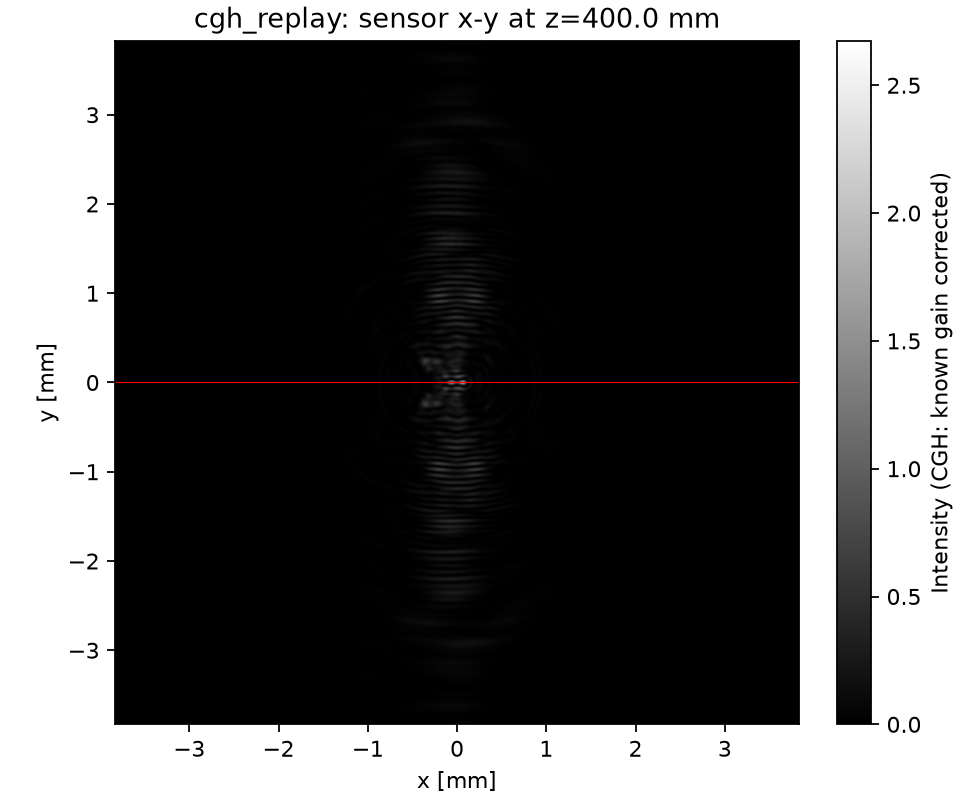

CGH画像: C:\Users\kota-\Github\Project_new\research\lsh_digit1_theory_outputs_v1\digit1_cgh_8bit.png


In [3]:
from IPython.display import Image, display
display(Image(filename=str(result_dir / 'digit1_sheet_comparison.png'), width=1300))
display(Image(filename=str(result_dir / 'thread_profile_design.png'), width=850))
# センサーのx-y画像。赤線y=0を抽出して上のx-zシートを作っています。
for filename in ('finite_complex_z0250.0mm.png', 'cgh_replay_z0250.0mm.png', 'cgh_replay_z0400.0mm.png'):
    image_path = result_dir / 'sensor_xy' / filename
    if image_path.is_file():
        display(Image(filename=str(image_path), width=550))
print('CGH画像:', (result_dir / 'digit1_cgh_8bit.png').resolve())
